In [100]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import curve_fit


In [157]:
n = 10000
bins = 100
x1 = np.random.normal(5,25,n)
y1 = np.random.normal(4,16,n)

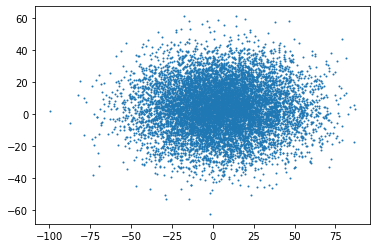

In [158]:
plt.scatter(x1, y1, s = 1)

(0.0, 319.0)

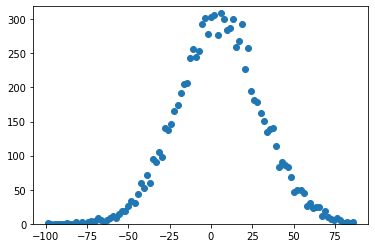

In [159]:
uniform_hist_x1 = np.histogram(x1, bins)
edges = uniform_hist_x1[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_x1[0])
plt.ylim(0,max(uniform_hist_x1[0]) + 10)

(0.0, 361.0)

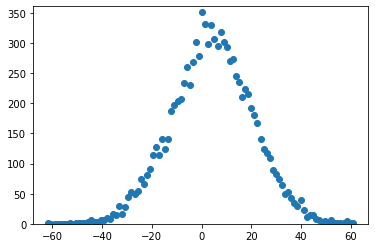

In [160]:
uniform_hist_y1 = np.histogram(y1, bins)
edges1 = uniform_hist_y1[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_y1[0])
plt.ylim(0,max(uniform_hist_y1[0]) + 10)

In [161]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2/(2*sigma**2))

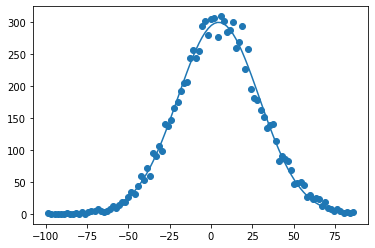

In [162]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_x1[0], p0=[uniform_hist_x1[0].max(), x1.mean(), x1.std()])
plt.scatter(centers, uniform_hist_x1[0])
plt.plot(centers, gauss(centers, *popt))

In [163]:
x_center = popt[1]

In [164]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_x1[0], p0=[uniform_hist_x1[0].max(), x1.mean(), x1.std()])
residuals = uniform_hist_x1[0] - gauss(centers, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_x1[0] - uniform_hist_x1[0].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

0.9911683646978676

0.991144399039477

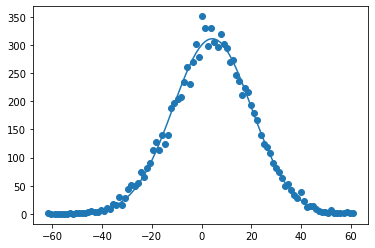

In [165]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_y1[0], p0=[uniform_hist_y1[0].max(), y1.mean(), y1.std()])
plt.scatter(centers1, uniform_hist_y1[0])
plt.plot(centers1, gauss(centers1, *popt))
residuals = uniform_hist_y1[0] - gauss(centers1, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_y1[0] - uniform_hist_y1[0].mean())**2)
r2_y = 1 - ss_res / ss_tot
r2_y

In [166]:
y_center = popt[1]

In [167]:
t = np.linspace(-10*np.pi,10*np.pi,300)

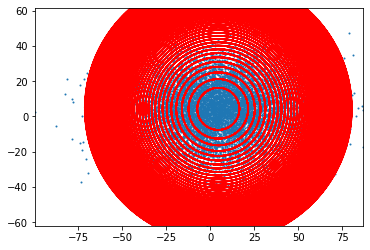

In [168]:
#fig, ax = plt.subplots()
r = 12
n_circ = 40
plt.scatter(x1, y1, s = 1)
for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(x1.min(), x1.max())
plt.ylim(y1.min(), y1.max())
plt.gca().set_aspect("equal")


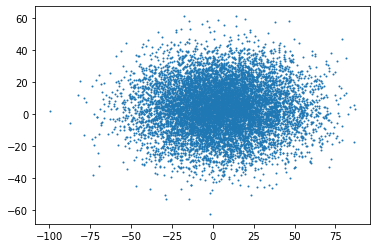

In [169]:
plt.scatter(x1, y1, s = 1)


In [176]:
counts = [0] * n_circ

for i in range(n_circ):
    for j in range(n):
        if (r*np.sqrt(i))**2<(x1[j]-x_center)**2 + (y1[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts[i] = counts[i] + 1
counts


[1675,
 1391,
 1089,
 926,
 739,
 614,
 484,
 465,
 351,
 321,
 268,
 209,
 208,
 166,
 136,
 126,
 110,
 98,
 84,
 82,
 59,
 44,
 46,
 36,
 39,
 37,
 20,
 19,
 24,
 21,
 17,
 8,
 12,
 1,
 13,
 10,
 3,
 11,
 3,
 5]

In [177]:
n

10000

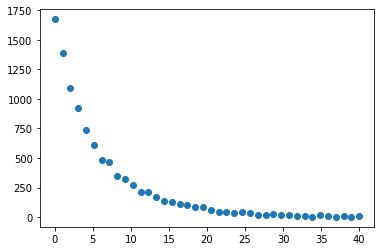

In [178]:
plt.scatter(np.linspace(0,n_circ,n_circ),counts)

In [179]:
sum(counts)

9970